# 07 — Baseline Model Development
**Day 7 · Phase 4: Machine Learning Development**

### Setup
- **Target:** price (₹). **Features:** the 9 cleaned inputs → 12 engineered → 29 encoded columns (Day 4).
- **Split:** the grouped train/test split from Day 4 (419 / 97 rows; no phone model in both). The **test set isn't
  used today**; it is reserved for the final evaluation on Day 9.
- **Evaluation:** **grouped 5-fold cross-validation** (`GroupKFold` by model) on the training set. Every fold
  validates on phone models the model never saw.
- **Leakage prevention:** every learned step (imputation medians, one-hot categories, scaling, the model) sits inside
  a `Pipeline`, so `cross_validate` re-fits it on each training fold only.

### Metrics
- **MAE** — average absolute error in rupees. Easy to explain: “on average we're off by ₹X”.
- **RMSE** — square root of the mean squared error. Penalises large misses more, so it's dominated by expensive phones.
- **R²** — share of price variance explained (1 = perfect, 0 = no better than predicting the mean, < 0 = worse).

### Models
| Model | Why it's here |
|---|---|
| Dummy (median) | The floor: always predicts the training median. Any useful model must beat it clearly. |
| Linear Regression | Additive, interpretable; with log target, coefficients act like % effects. Needs scaled inputs. |
| Decision Tree | Captures thresholds and interactions; prone to overfitting. |
| Random Forest | Averages many de-correlated trees → lower variance than one tree. |

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from sklearn.model_selection import KFold
from src.train import load_model_ready_data, xy, group_cv, baseline_models
from src.evaluate import compare_models

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)
print(f"Training rows: {len(X_tr)} | models: {g_tr.nunique()} | test set held back: {len(test)} rows")

Training rows: 419 | models: 137 | test set held back: 97 rows


## 1. Baselines with log-price target (grouped 5-fold CV)

In [2]:
base_log = compare_models(baseline_models(log_target=True), X_tr, y_tr, group_cv(), g_tr)
base_log.round(3)

,train_MAE,cv_MAE,cv_MAE_std,train_RMSE,cv_RMSE,train_R2,cv_R2,cv_R2_std,fit_time_s
model,,,,,,,,,
Linear Regression,"1,749.509","2,329.740",618.036,"2,655.466","4,016.375",0.938,0.845,0.076,0.023
Random Forest,444.833,"2,958.714",995.984,989.361,"5,599.150",0.991,0.704,0.195,0.276
Decision Tree,123.543,"3,470.006","1,071.230",412.914,"5,854.728",0.998,0.667,0.184,0.018
Dummy (median),"7,239.473","7,410.806","1,505.196","11,002.664","10,694.605",-0.057,-0.122,0.123,0.018


**Interpretation.**
- The **Dummy** model misses by ~₹7,400 on average and has negative R²: this is the bar to beat.
- **Linear Regression** is the best baseline under grouped CV (MAE ≈ ₹2,330, R² ≈ 0.85), about a **69 % reduction
  in error** vs the dummy.
- **Decision Tree** and **Random Forest** fit training data almost perfectly (train MAE ₹124 and ₹445) but generalise
  worse than the linear model (CV MAE ₹3,470 and ₹2,959). **That's overfitting:** trees memorise phone-specific
  combinations that don't carry over to new models, while the linear model's simple additive structure in log space
  transfers better.
- Fold-to-fold standard deviations are large (₹600–1,100): with ~27 models per fold, results depend on which phones
  land in a fold. Differences of a few hundred rupees between models aren't meaningful on their own.

## 2. Does the log target help?
Same models trained on raw price instead of log price.

In [3]:
base_raw = compare_models(baseline_models(log_target=False), X_tr, y_tr, group_cv(), g_tr)
target_cmp = pd.DataFrame({"cv_MAE (log target)": base_log["cv_MAE"], "cv_MAE (raw target)": base_raw["cv_MAE"],
                           "cv_R2 (log target)": base_log["cv_R2"], "cv_R2 (raw target)": base_raw["cv_R2"]})
target_cmp["MAE change from log"] = target_cmp["cv_MAE (log target)"] - target_cmp["cv_MAE (raw target)"]
target_cmp.round(3)

,cv_MAE (log target),cv_MAE (raw target),cv_R2 (log target),cv_R2 (raw target),MAE change from log
model,,,,,
Linear Regression,"2,329.740","2,738.099",0.845,0.803,-408.359
Random Forest,"2,958.714","2,757.195",0.704,0.772,201.519
Decision Tree,"3,470.006","3,238.368",0.667,0.699,231.639
Dummy (median),"7,410.806","7,410.806",-0.122,-0.122,0.000


**Interpretation.** The effect depends on the model:
- **Linear Regression improves a lot with log price** (MAE ₹2,738 → ₹2,330; R² 0.80 → 0.85). Price effects are
  **multiplicative** (a flagship chip adds a percentage, not a fixed rupee amount), which becomes additive in log space.
- **The untuned trees get slightly worse** (Random Forest ₹2,757 → ₹2,959; Decision Tree ₹3,238 → ₹3,470). A tree's
  leaf predicts the *mean of log prices*, which converts back to a geometric mean — lower than the arithmetic mean —
  so deep, overfitted trees systematically under-predict expensive phones in rupee terms.

**Decision: log target from here on**, because the best model uses it, and Day 8 re-checks the choice for tuned
boosting (where log wins: MAE ₹2,469 vs ₹2,606 with raw price).

## 3. Why grouped CV? Comparing with a random split
The same models evaluated with an ordinary shuffled `KFold`, where colour variants of a phone can sit in both the
training and validation folds.

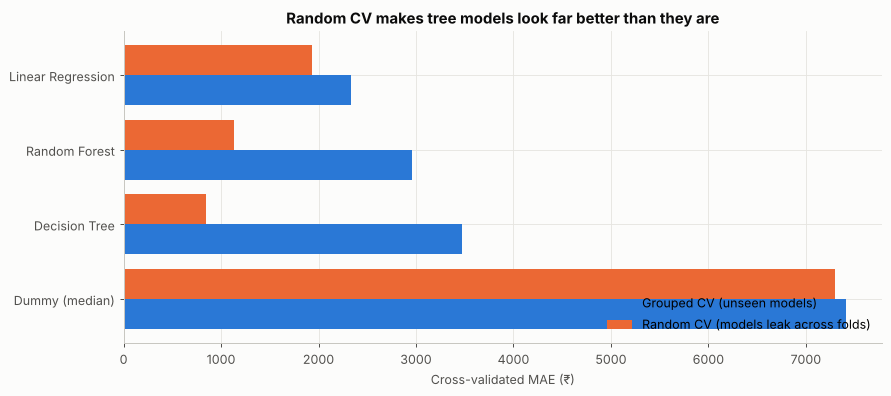

,grouped CV MAE,random CV MAE,grouped CV R²,random CV R²,optimism (₹)
model,,,,,
Linear Regression,"2,329.740","1,928.426",0.845,0.913,401.315
Random Forest,"2,958.714","1,135.285",0.704,0.951,"1,823.429"
Decision Tree,"3,470.006",847.407,0.667,0.936,"2,622.600"
Dummy (median),"7,410.806","7,297.368",-0.122,-0.067,113.438


In [4]:
base_random = compare_models(baseline_models(log_target=True), X_tr, y_tr, KFold(5, shuffle=True, random_state=RANDOM_STATE))
cv_cmp = pd.DataFrame({"grouped CV MAE": base_log["cv_MAE"], "random CV MAE": base_random["cv_MAE"],
                       "grouped CV R²": base_log["cv_R2"], "random CV R²": base_random["cv_R2"]})
cv_cmp["optimism (₹)"] = cv_cmp["grouped CV MAE"] - cv_cmp["random CV MAE"]
cv_cmp = cv_cmp.sort_values("grouped CV MAE")

fig, ax = plt.subplots(figsize=(10, 4.5))
yy = np.arange(len(cv_cmp))
ax.barh(yy + 0.2, cv_cmp["grouped CV MAE"], height=0.4, color=PRIMARY, label="Grouped CV (unseen models)")
ax.barh(yy - 0.2, cv_cmp["random CV MAE"], height=0.4, color=ACCENT, label="Random CV (models leak across folds)")
ax.set_yticks(yy, cv_cmp.index); ax.invert_yaxis()
ax.set(title="Random CV makes tree models look far better than they are", xlabel="Cross-validated MAE (₹)")
ax.legend(loc="lower right"); fig.tight_layout(); save_fig(fig, "model_grouped_vs_random_cv")
cv_cmp.round(3)

**Interpretation — the most important methodological result of the project.**
Under a random split the **Decision Tree looks like the best model (MAE ≈ ₹850, R² ≈ 0.94)**. Under grouped CV it is
the worst real model (≈ ₹3,470). The tree simply recognises a colour variant of a phone it has already seen and
copies its price. The ranking flips: Linear Regression is best when the question is “price a phone model we haven't
seen”, which is the actual business use case.

**Every result from here on uses grouped CV.** Reporting random-split scores would overstate accuracy by up to ~4×
for tree models.

## 4. Baseline results table

In [5]:
baseline_table = base_log[["train_MAE", "cv_MAE", "cv_MAE_std", "train_RMSE", "cv_RMSE", "train_R2", "cv_R2", "fit_time_s"]]
baseline_table.to_csv(PROJECT_ROOT / "reports" / "baseline_results.csv")
dummy_mae = baseline_table.loc["Dummy (median)", "cv_MAE"]
baseline_table.assign(**{"MAE reduction vs dummy": 1 - baseline_table["cv_MAE"] / dummy_mae}).round(3)

,train_MAE,cv_MAE,cv_MAE_std,train_RMSE,cv_RMSE,train_R2,cv_R2,fit_time_s,MAE reduction vs dummy
model,,,,,,,,,
Linear Regression,"1,749.509","2,329.740",618.036,"2,655.466","4,016.375",0.938,0.845,0.023,0.686
Random Forest,444.833,"2,958.714",995.984,989.361,"5,599.150",0.991,0.704,0.276,0.601
Decision Tree,123.543,"3,470.006","1,071.230",412.914,"5,854.728",0.998,0.667,0.018,0.532
Dummy (median),"7,239.473","7,410.806","1,505.196","11,002.664","10,694.605",-0.057,-0.122,0.018,0.000


## Conclusions
1. All real models beat the dummy by a wide margin, so the specifications contain substantial price information.
2. **Linear Regression on log price is the strongest baseline** under the realistic, grouped evaluation.
3. Tree models **overfit**: near-perfect training scores, worse validation. Day 8 tunes them (depth, leaf size,
   learning rate) and tests boosting, which often generalises better than a single deep tree.
4. Log price helps; grouped CV is essential.